# Day 3: Exploratory Data Analysis (EDA)

## Project Overview
This project focuses on Exploratory Data Analysis using Python.

The main objective is to understand employee data through
statistical analysis and data visualization.

### Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Objectives
1. Understand the dataset.
2. Analyze data distributions.
3. Identify patterns and trends.
4. Study correlations between numerical variables.
5. Create meaningful visualizations.
6. Write five evidence-based observations.

In [60]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [61]:
# Load employee dataset

from pathlib import Path

DATA_PATH = Path("../data/employees.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [62]:
# Display first five rows

df.head()

,employee_id,name,age,department,salary,joining_date,experience,city
0,101,Amit,22,IT,25000,2020-01-01,0.0,Nagpur
1,102,Riya,25,HR,26750,2020-01-20,0.7,Pune
2,103,Rahul,28,Finance,28500,2020-02-08,1.4,Mumbai
3,104,Neha,31,Sales,30250,2020-02-27,2.1,Nashik
4,105,Akash,NaN,IT,32000,2020-03-17,2.8,Amravati


In [63]:
# Check number of rows and columns

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 100
Number of Columns: 8


In [64]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['employee_id', 'name', 'age', 'department', 'salary', 'joining_date', 'experience', 'city']


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   employee_id   100 non-null    int64  
 1   name          100 non-null    object 
 2   age           99 non-null     object 
 3   department    99 non-null     object 
 4   salary        99 non-null     object 
 5   joining_date  100 non-null    object 
 6   experience    100 non-null    float64
 7   city          99 non-null     object 
dtypes: float64(1), int64(1), object(6)
memory usage: 6.4+ KB


In [66]:
df.describe()

,employee_id,experience
count,100.000000,100.000000
mean,150.000000,4.240000
std,29.430624,2.596696
min,101.000000,0.000000
25%,124.750000,2.075000
50%,149.500000,4.200000
75%,175.250000,6.325000
max,200.000000,8.900000


In [67]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
employee_id     0
name            0
age             1
department      1
salary          1
joining_date    0
experience      0
city            1
dtype: int64


In [68]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 1


In [69]:
print("Unique Departments:")
print(df["department"].unique())

print("\nUnique Cities:")
print(df["city"].unique())

Unique Departments:
['IT' 'HR' 'Finance' 'Sales' 'it' nan 'HR ']

Unique Cities:
['Nagpur' 'Pune' 'Mumbai' 'Nashik' 'Amravati' 'Aurangabad' nan]


## Data Cleaning and Preparation

In [70]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage.round(2))

Missing Values in Each Column:
employee_id     0
name            0
age             1
department      1
salary          1
joining_date    0
experience      0
city            1
dtype: int64

Missing Value Percentage:
employee_id     0.0
name            0.0
age             1.0
department      1.0
salary          1.0
joining_date    0.0
experience      0.0
city            1.0
dtype: float64


In [71]:
print("Age Data Type:", df["age"].dtype)
print("Salary Data Type:", df["salary"].dtype)

print("\nAge Values:")
print(df["age"].head(10).tolist())

print("\nSalary Values:")
print(df["salary"].head(10).tolist())

Age Data Type: object
Salary Data Type: object

Age Values:
['22', '25', '28', '31', nan, '37', '40', '43', '22', '25']

Salary Values:
['25000', '26750', '28500', '30250', '32000', '33750', '35500', nan, '39000', '40750']


In [72]:
# Convert object columns into numeric data types
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")
df["experience"] = pd.to_numeric(df["experience"], errors="coerce")

print("Updated Data Types:")
print(df.dtypes)

Updated Data Types:
employee_id       int64
name             object
age             float64
department       object
salary          float64
joining_date     object
experience      float64
city             object
dtype: object


In [73]:
# Fill numerical missing values using median
df["age"] = df["age"].fillna(df["age"].median())
df["salary"] = df["salary"].fillna(df["salary"].median())

# Fill categorical missing values using mode
df["department"] = df["department"].fillna(df["department"].mode()[0])
df["city"] = df["city"].fillna(df["city"].mode()[0])

print("Missing values handled successfully!")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing values handled successfully!

Missing Values After Cleaning:
employee_id     0
name            0
age             0
department      0
salary          0
joining_date    0
experience      0
city            0
dtype: int64


In [74]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 1


In [75]:
# Display duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate Records:")
display(duplicate_rows)

Duplicate Records:


,employee_id,name,age,department,salary,joining_date,experience,city
0,101,Amit,22.0,IT,25000.0,2020-01-01,0.0,Nagpur
50,101,Amit,22.0,IT,25000.0,2020-01-01,0.0,Nagpur


In [76]:
# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate records removed successfully!")

# Verify duplicate records
print("Duplicates after cleaning:", df.duplicated().sum())

# Check updated dataset shape
print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Duplicates after cleaning: 0
Updated Dataset Shape: (99, 8)


In [77]:
# Check invalid age values
invalid_ages = df[(df["age"] < 18) | (df["age"] > 60)]

print("Invalid Age Records:")
display(invalid_ages[["employee_id", "name", "age"]])

print("Total Invalid Age Records:", len(invalid_ages))


Invalid Age Records:


,employee_id,name,age
60,161,Amit,-5.0
72,173,Sneha,150.0


Total Invalid Age Records: 2


In [78]:
# Replace invalid ages with NaN
df.loc[(df["age"] < 18) | (df["age"] > 60), "age"] = np.nan

# Fill invalid and missing ages using median
df["age"] = df["age"].fillna(df["age"].median())

print("Invalid ages handled successfully!")

# Verify age range
print("\nMinimum Age:", df["age"].min())
print("Maximum Age:", df["age"].max())

# Check remaining invalid ages
print("Remaining Invalid Ages:",
      len(df[(df["age"] < 18) | (df["age"] > 60)]))

Invalid ages handled successfully!

Minimum Age: 22.0
Maximum Age: 43.0
Remaining Invalid Ages: 0


In [79]:
# Final data cleaning verification

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nData Cleaning Completed Successfully!")

Dataset Shape: (99, 8)

Missing Values:
employee_id     0
name            0
age             0
department      0
salary          0
joining_date    0
experience      0
city            0
dtype: int64

Duplicate Records: 0

Data Types:
employee_id       int64
name             object
age             float64
department       object
salary          float64
joining_date     object
experience      float64
city             object
dtype: object

Data Cleaning Completed Successfully!


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the dataset through summary statistics and visualizations. It helps identify patterns, distributions, relationships, and trends in the data.

In [80]:
# Generate summary statistics
print("Summary Statistics:")
display(df.describe())

Summary Statistics:


,employee_id,age,salary,experience
count,99.000000,99.000000,99.000000,99.000000
mean,150.494949,32.242424,47429.292929,4.282828
std,29.159090,6.803497,15253.765026,2.574167
min,101.000000,22.000000,-5000.000000,0.000000
25%,125.500000,26.500000,35375.000000,2.100000
50%,150.000000,31.000000,46250.000000,4.200000
75%,175.500000,37.000000,59375.000000,6.350000
max,200.000000,43.000000,74750.000000,8.900000


In [81]:
# Identify invalid salary records
invalid_salary = df[df["salary"] <= 0]

print("Invalid Salary Records:")
display(invalid_salary[["employee_id", "name", "salary", "department"]])

print("Total Invalid Salary Records:", len(invalid_salary))

Invalid Salary Records:


,employee_id,name,salary,department
81,182,Riya,-5000.0,HR


Total Invalid Salary Records: 1


In [82]:
# Replace invalid salary with NaN
df.loc[df["salary"] <= 0, "salary"] = np.nan

# Fill missing salary using median
df["salary"] = df["salary"].fillna(df["salary"].median())

print("Invalid salary handled successfully!")

print("\nMinimum Salary:", df["salary"].min())
print("Maximum Salary:", df["salary"].max())

print("\nRemaining Invalid Salaries:",
      (df["salary"] <= 0).sum())

Invalid salary handled successfully!

Minimum Salary: 25000.0
Maximum Salary: 74750.0

Remaining Invalid Salaries: 0


### 1. Age Distribution


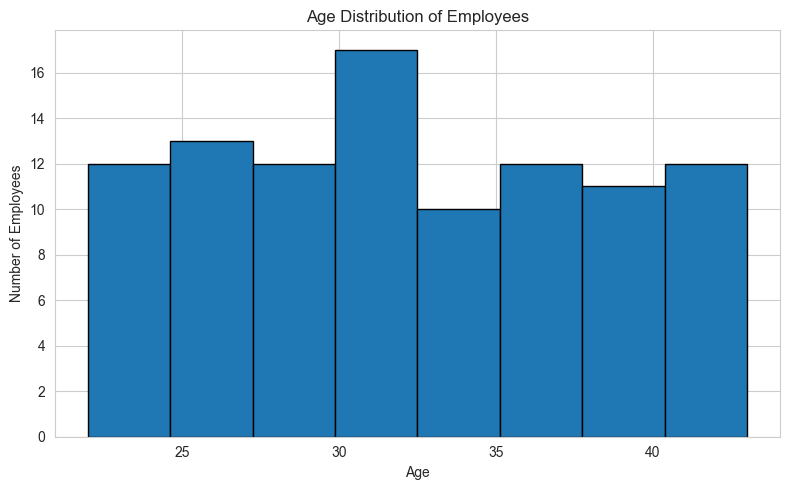

In [96]:
# Age Distribution Histogram
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=8, edgecolor="black")

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.savefig("../reports/plots/age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation 1:** The age distribution shows that most employees belong to the 30–33 years age group. The dataset contains employees aged approximately 22 to 43 years.

### 2. Department-wise Employee Count


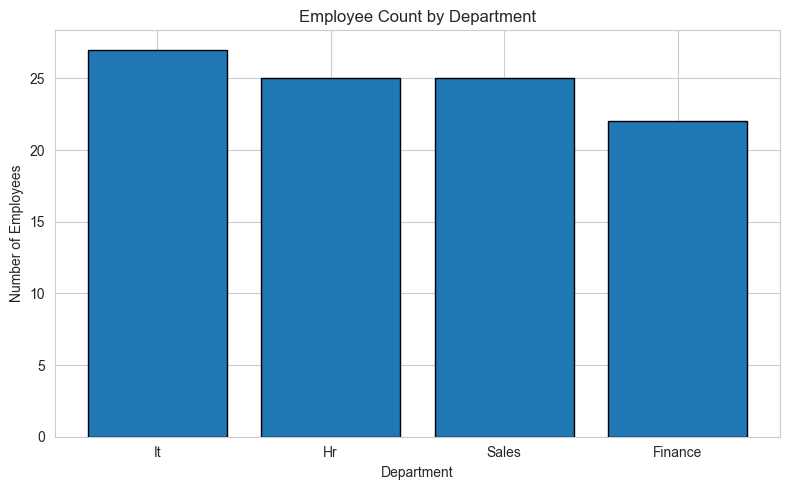

In [92]:
# Count employees in each department
department_counts = df["department"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(department_counts.index, department_counts.values,
        edgecolor="black")

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.savefig("../reports/plots/department_employee_count.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation 2:** The bar chart compares the number of employees across different departments. It helps identify departments with the highest and lowest employee counts and understand the distribution of employees within the organization.

### 3. Salary Distribution

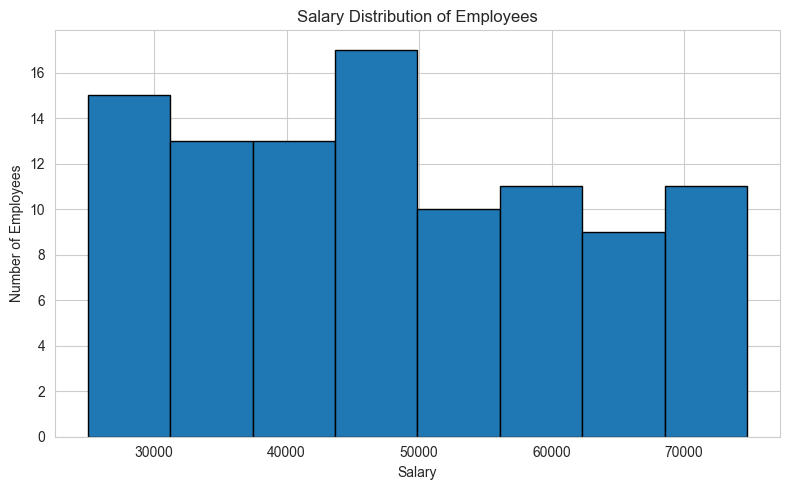

In [93]:
# Salary Distribution Histogram
plt.figure(figsize=(8, 5))

plt.hist(df["salary"], bins=8, edgecolor="black")

plt.title("Salary Distribution of Employees")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.savefig("../reports/plots/salary_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation 3:** The salary distribution shows how employee salaries are spread across different salary ranges. It helps identify the salary range where most employees are concentrated.

### 4. Salary Comparison Across Departments

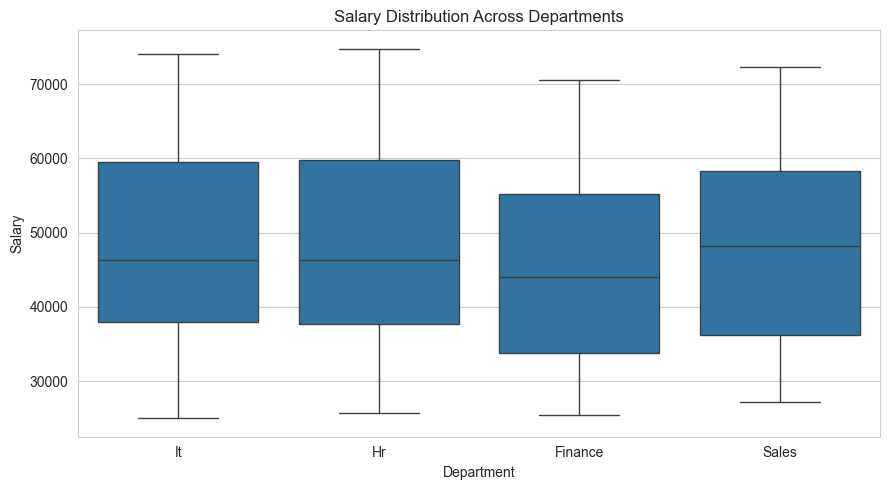

In [94]:
# Salary Comparison Across Departments
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="department", y="salary")

plt.title("Salary Distribution Across Departments")
plt.xlabel("Department")
plt.ylabel("Salary")

plt.tight_layout()
plt.savefig("../reports/plots/salary_by_department.png", dpi=300, bbox_inches="tight")
plt.show()

### 5. Correlation Heatmap

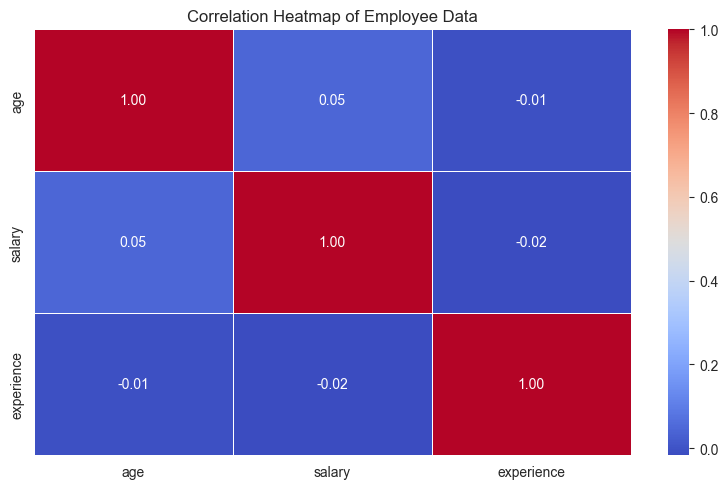

In [95]:
# Select relevant numerical columns
numeric_df = df[["age", "salary", "experience"]]

# Calculate correlation
correlation_matrix = numeric_df.corr()

# Create correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Employee Data")
plt.tight_layout()
plt.savefig("../reports/plots/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation 5:** The correlation heatmap shows the strength and direction of relationships between numerical variables such as age, salary, and experience. Positive correlation indicates that two variables tend to increase together, while negative correlation indicates an opposite relationship.

## EDA Findings and Observations

In [88]:
# Generate important EDA findings

print("1. Age Statistics:")
print(df["age"].describe())

print("\n2. Department-wise Employee Count:")
print(df["department"].value_counts())

print("\n3. Salary Statistics:")
print(df["salary"].describe())

print("\n4. Average Salary by Department:")
print(df.groupby("department")["salary"].mean().round(2))

print("\n5. Correlation Matrix:")
print(df[["age", "salary", "experience"]].corr().round(2))

1. Age Statistics:
count    99.000000
mean     32.242424
std       6.803497
min      22.000000
25%      26.500000
50%      31.000000
75%      37.000000
max      43.000000
Name: age, dtype: float64

2. Department-wise Employee Count:
department
IT         26
Sales      25
HR         24
Finance    22
it          1
HR          1
Name: count, dtype: int64

3. Salary Statistics:
count       99.000000
mean     47948.232323
std      14295.710901
min      25000.000000
25%      35750.000000
50%      46375.000000
75%      59375.000000
max      74750.000000
Name: salary, dtype: float64

4. Average Salary by Department:
department
Finance    45500.00
HR         47942.71
HR         56500.00
IT         49269.23
Sales      48610.00
it         42500.00
Name: salary, dtype: float64

5. Correlation Matrix:
             age  salary  experience
age         1.00    0.05       -0.01
salary      0.05    1.00       -0.02
experience -0.01   -0.02        1.00


In [89]:
df["department"] = df["department"].str.strip().str.title()

print("Department-wise Employee Count:")
print(df["department"].value_counts())

Department-wise Employee Count:
department
It         27
Hr         25
Sales      25
Finance    22
Name: count, dtype: int64


In [90]:
print("1. Age Statistics:")
print(df["age"].describe().to_string())

print("\n2. Department-wise Employee Count:")
print(df["department"].value_counts().to_string())

print("\n3. Salary Statistics:")
print(df["salary"].describe().to_string())

print("\n4. Average Salary by Department:")
print(df.groupby("department")["salary"].mean().round(2).to_string())

print("\n5. Correlation Matrix:")
print(df[["age", "salary", "experience"]].corr().round(2).to_string())

1. Age Statistics:
count    99.000000
mean     32.242424
std       6.803497
min      22.000000
25%      26.500000
50%      31.000000
75%      37.000000
max      43.000000

2. Department-wise Employee Count:
department
It         27
Hr         25
Sales      25
Finance    22

3. Salary Statistics:
count       99.000000
mean     47948.232323
std      14295.710901
min      25000.000000
25%      35750.000000
50%      46375.000000
75%      59375.000000
max      74750.000000

4. Average Salary by Department:
department
Finance    45500.00
Hr         48285.00
It         49018.52
Sales      48610.00

5. Correlation Matrix:
             age  salary  experience
age         1.00    0.05       -0.01
salary      0.05    1.00       -0.02
experience -0.01   -0.02        1.00


## Key EDA Observations

**Observation 1 – Age Distribution:**  
The dataset contains 99 employees. The average employee age is approximately 32 years. The minimum age is 22 years, and the maximum age is 43 years. Most employees fall within the age range of 26 to 37 years.

**Observation 2 – Department-wise Employee Count:**  
The IT department has the highest number of employees (27), followed by HR and Sales with 25 employees each. The Finance department has 22 employees. This shows the distribution of employees across four departments.

**Observation 3 – Salary Distribution:**  
The average employee salary is approximately ₹47,948. The minimum salary is ₹25,000, while the median salary is ₹46,375. The maximum salary is ₹74,750. This indicates variation in employee salaries.

**Observation 4 – Average Salary by Department:**  
The average salary by department helps compare salary levels across IT, HR, Sales, and Finance. It provides an understanding of salary differences between departments.

**Observation 5 – Correlation Analysis:**  
The correlation matrix shows very weak relationships between age, salary, and experience. Age and salary have a correlation of 0.05, while age and experience have -0.01, and salary and experience have -0.02. These values indicate almost no linear correlation between the variables.

##  Data Visualization

In this section, Matplotlib and Seaborn are used to create graphs and understand employee data through visual representations.

In [97]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_employee_data
from src.visualization import (
    plot_age_distribution,
    plot_department_count,
    plot_salary_distribution,
    plot_salary_by_department,
    plot_correlation_heatmap
)

print("All modules imported successfully!")

All modules imported successfully!


In [98]:
test_df = load_employee_data("../data/employees.csv")

print("Data loaded successfully using data_loader.py!")
print("Dataset Shape:", test_df.shape)
display(test_df.head())

Data loaded successfully using data_loader.py!
Dataset Shape: (100, 8)


,employee_id,name,age,department,salary,joining_date,experience,city
0,101,Amit,22,IT,25000,2020-01-01,0.0,Nagpur
1,102,Riya,25,HR,26750,2020-01-20,0.7,Pune
2,103,Rahul,28,Finance,28500,2020-02-08,1.4,Mumbai
3,104,Neha,31,Sales,30250,2020-02-27,2.1,Nashik
4,105,Akash,NaN,IT,32000,2020-03-17,2.8,Amravati


In [100]:
print(test_df[["age", "salary", "experience"]].dtypes)

print("\nFirst 10 age values:")
print(test_df["age"].head(10).tolist())

age            object
salary         object
experience    float64
dtype: object

First 10 age values:
['22', '25', '28', '31', nan, '37', '40', '43', '22', '25']


(array([12., 13., 12., 17., 10., 12., 11., 12.]),
 array([22.   , 24.625, 27.25 , 29.875, 32.5  , 35.125, 37.75 , 40.375,
        43.   ]),
 <BarContainer object of 8 artists>)

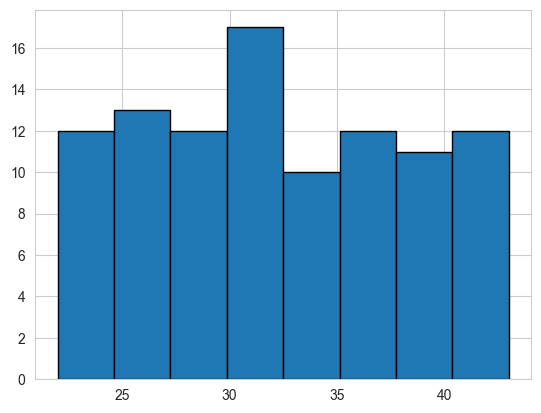

In [103]:
plt.hist(df["age"], bins=8, edgecolor="black")

In [105]:
from pathlib import Path
import src.visualization as visualization
import inspect

print("File Location:")
print(visualization.__file__)

print("\nFunction Code:")
print(inspect.getsource(visualization.plot_salary_distribution))

File Location:
c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-03\src\visualization.py

Function Code:
def plot_department_count(df):
    df = prepare_data(df)
    department_counts = df["department"].value_counts()

    plt.figure(figsize=(8, 5))
    plt.bar(department_counts.index, department_counts.values,
            edgecolor="black")
    plt.title("Employee Count by Department")
    plt.xlabel("Department")
    plt.ylabel("Number of Employees")
    plt.tight_layout()
    plt.show()



In [106]:
import importlib
import src.visualization as visualization

importlib.reload(visualization)

plot_department_count = visualization.plot_department_count
plot_salary_distribution = visualization.plot_salary_distribution
plot_salary_by_department = visualization.plot_salary_by_department
plot_correlation_heatmap = visualization.plot_correlation_heatmap

print("All visualization functions updated successfully!")

All visualization functions updated successfully!


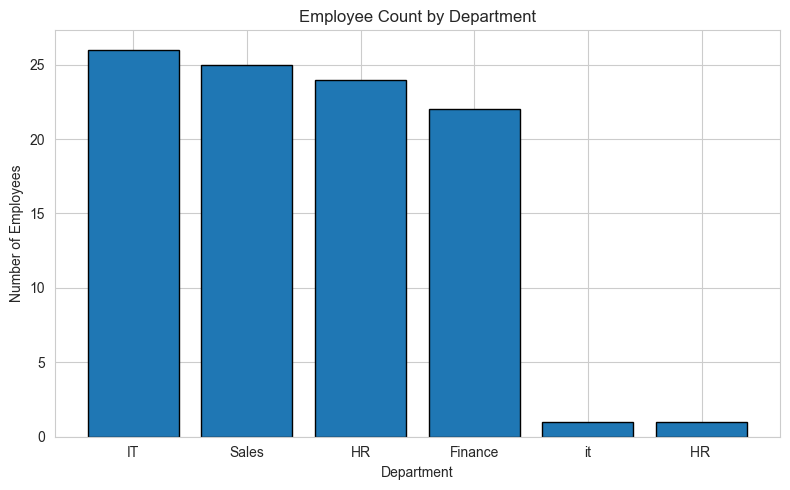

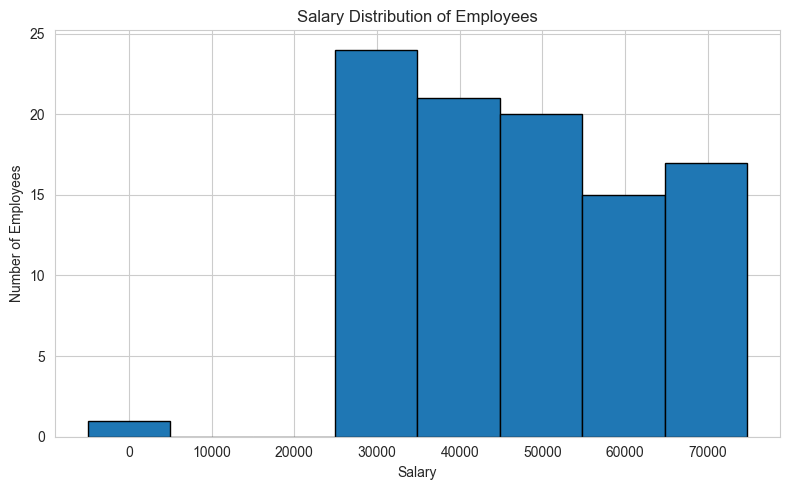

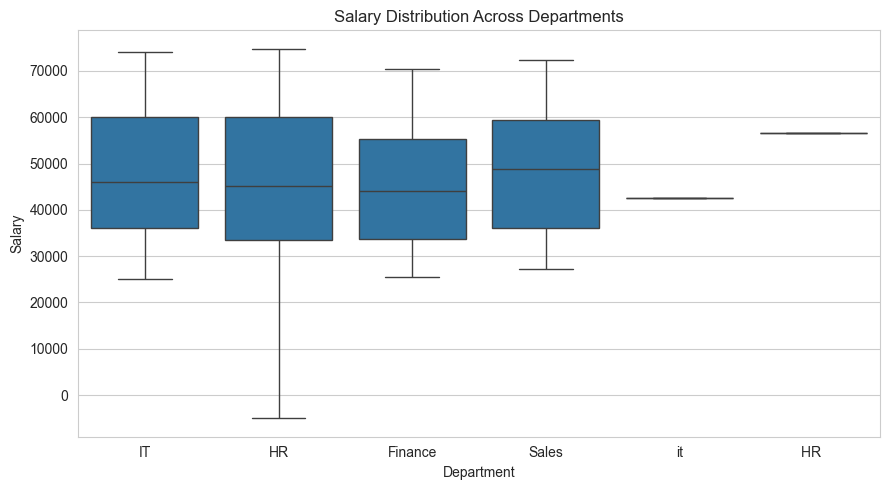

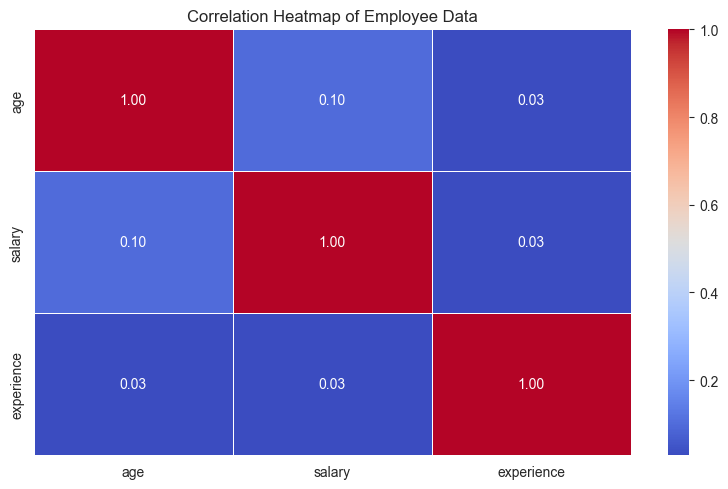

In [107]:
plot_department_count(test_df)
plot_salary_distribution(test_df)
plot_salary_by_department(test_df)
plot_correlation_heatmap(test_df)

##  Conclusion

The Exploratory Data Analysis (EDA) of the employee dataset was successfully completed using Python. The project involved data cleaning, statistical analysis, and visualization to identify meaningful patterns and insights.

This project strengthened my practical knowledge of Pandas, NumPy, Matplotlib, and Seaborn, along with the fundamentals of data analysis and visualization.